In [153]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [154]:
import numpy as np
from mytools.halo_new import get_coord, get_mask_sector, get_mask_square, generate_local_noise_weights
from mytools.plot import plot_heatmap, plot_stack_fit_res, plot_axlines, plot_hist, plot_line_diff, make_figure, set_ticks, plt
from crafts_stack.halo_fitting import build_model, halofit, cov_to_err_map
from astropy.stats import sigma_clip

<Axes: title={'center': 'Test'}, xlabel='X', ylabel='Y'>

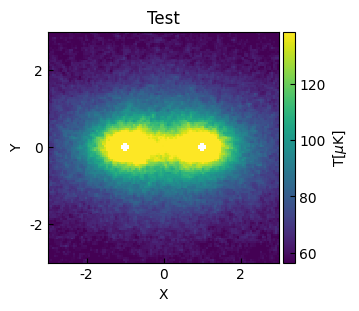

In [155]:
data = np.load('../data/tng_pairstack_result_cube.npz', 'r')['data']
# data = np.load('../data/tng_pairstack_result_hpmap.npz', 'r')['data']
# data = np.load('../data/crafts_pairstack_result_airpls.npz', 'r')['data']

data = sigma_clip(data, sigma=10, masked=True)
plot_heatmap(data, title='Test')

In [156]:
coord = get_coord()

name = 'nfw'
# bg_name = 'poly'
bg_name = 'const'

tolenrance = 0.1

bounds = {
    'amplitude_0': (0, 200),
    'amplitude_1': (0, 200),
    # 'x_mean_0': (-1 - tolenrance, -1 + tolenrance),
    # 'x_mean_1': (1 - tolenrance, 1 + tolenrance),
    # 'y_mean_0': (0 - tolenrance, 0 + tolenrance),
    # 'y_mean_1': (0 - tolenrance, 0 + tolenrance),
    'ellipticity_0': (0, 0.5),
    'ellipticity_1': (0, 0.5),
    # 'theta_0': (0, 10),
    # 'theta_1': (0, 10),
    # 'r_s_0': (0.1, 10),
    # 'r_s_1': (0.1, 10),
}

constraints = {
    # "fixed": ['ellipticity_0', 'ellipticity_1'],
    "fixed": ['x_mean_0', 'y_mean_0', 'x_mean_1', 'y_mean_1'], # fix the center of the two NFW profiles
    "tied": [
        # ("amplitude_1", "amplitude_0"),  # amplitude_1 = amplitude_0
        ("ellipticity_1", "ellipticity_0"),
        # ("r_s_1", "r_s_2"),
        # ('c0_0_2', 'c0_0_3'),  
        # ('c1_0_2', 'c1_0_3'),  
        # ('c2_0_2', 'c2_0_3'), 
        # ('c0_1_2', 'c0_1_3'),
        # ('c0_2_2', 'c0_2_3'),
        # ('c1_1_2', 'c1_1_3'),
    ]
}

init_bg = {
    # "degree": 2
}

model = build_model(name, bg_name, init_bg=init_bg, bounds=bounds, constraints=constraints)
print(model)

Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2]
Components: 
    [0]: <NFW2D(amplitude=50., x_mean=-1., y_mean=0., r_s=0.5, ellipticity=0., theta=0.)>

    [1]: <NFW2D(amplitude=50., x_mean=1., y_mean=0., r_s=0.5, ellipticity=0., theta=0.)>

    [2]: <Const2D(amplitude=1.)>
Parameters:
    amplitude_0 x_mean_0 y_mean_0 r_s_0 ... r_s_1 ellipticity_1 theta_1 amplitude_2
    ----------- -------- -------- ----- ... ----- ------------- ------- -----------
           50.0     -1.0      0.0   0.5 ...   0.5           0.0     0.0         1.0


<Axes: title={'center': 'Weight'}, xlabel='X', ylabel='Y'>

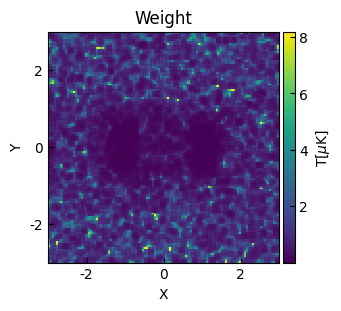

In [157]:
weights = generate_local_noise_weights(data)
# weights = read_h5(weight_path, 'crafts_122k/weight')
plot_heatmap(weights, title='Weight', q=0.1)

# without mask

In [158]:
data_list, fit_model, fit_info = halofit(coord, data, model=model, print_model=True, weights=weights)


Fitted double NFW model:
Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2]
Components: 
    [0]: <NFW2D(amplitude=4.06811114, x_mean=-1., y_mean=0., r_s=12.79033961, ellipticity=0.2914053, theta=-0.05422755)>

    [1]: <NFW2D(amplitude=2.12418708, x_mean=1., y_mean=0., r_s=23.9819072, ellipticity=0.2914053, theta=-0.01830327)>

    [2]: <Const2D(amplitude=43.07893785)>
Parameters:
       amplitude_0    x_mean_0 y_mean_0 ...        theta_1           amplitude_2    
    ----------------- -------- -------- ... --------------------- ------------------
    4.068111140248083     -1.0      0.0 ... -0.018303270792389782 43.078937854661795

Goodness of fit:
Chi-squared: 1706523.358
Reduced chi-squared: 118.616
RMS residual: 10.895



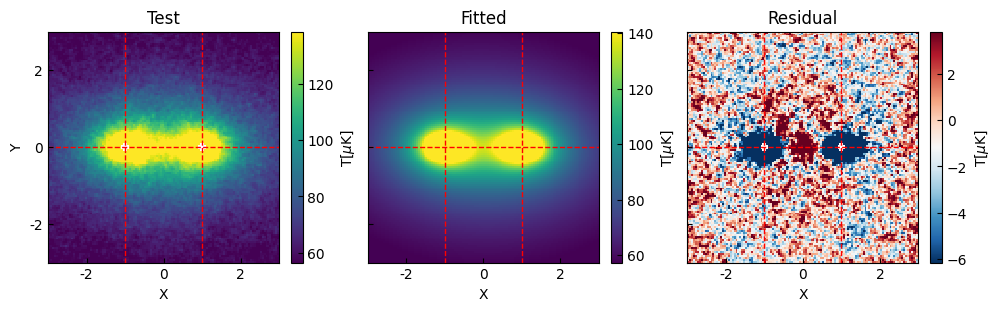

In [159]:
title = ['Test', 'Fitted', 'Residual']
axes =  plot_stack_fit_res(data_list, title=title)
# axes =  plot_stack_fit_res(data_list, title=title, vmax=[140,140, 20], vmin=[60, 60, -20])
plot_axlines(ax=axes, vl=[40, 80], hl=[60])

<Axes: title={'center': 'Error Map'}, xlabel='X', ylabel='Y'>

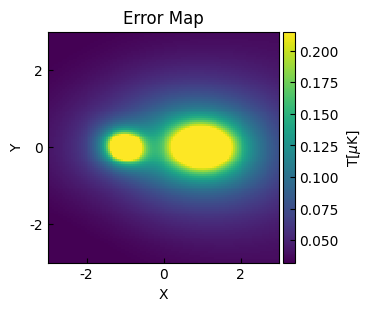

In [160]:
error_map = cov_to_err_map(fit_model, fit_info, *coord)
plot_heatmap(error_map, title='Error Map') 

# with mask sector 

<Axes: title={'center': 'Mask'}, xlabel='X', ylabel='Y'>

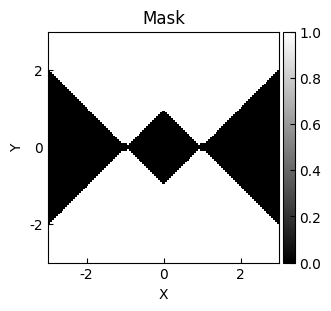

In [161]:
# mask_sector = get_mask_sector(coord=coord)
mask_sector = get_mask_sector(rlim=[0.1,5], coord=coord)
# mask_sector = get_mask_sector(thetalim=[-np.pi/3, np.pi/3], coord=coord)
plot_heatmap(mask_sector, title='Mask', cmap='gray', cbar_label='')

In [162]:
data_list_sector, fit_model, fit_info = halofit(coord, data, model=model, mask=mask_sector, print_model=True, weights=weights[mask_sector])


Fitted double NFW model:
Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2]
Components: 
    [0]: <NFW2D(amplitude=10.84222404, x_mean=-1., y_mean=0., r_s=5.78534159, ellipticity=0.26204312, theta=-0.0797135)>

    [1]: <NFW2D(amplitude=10.41821241, x_mean=1., y_mean=0., r_s=6.01000216, ellipticity=0.26204312, theta=-0.0260115)>

    [2]: <Const2D(amplitude=47.98084489)>
Parameters:
       amplitude_0     x_mean_0 y_mean_0 ...       theta_1          amplitude_2    
    ------------------ -------- -------- ... ------------------- ------------------
    10.842224039941309     -1.0      0.0 ... -0.0260115012357593 47.980844891144145

Goodness of fit:
Chi-squared: 1459922.246
Reduced chi-squared: 141.260
RMS residual: 11.878



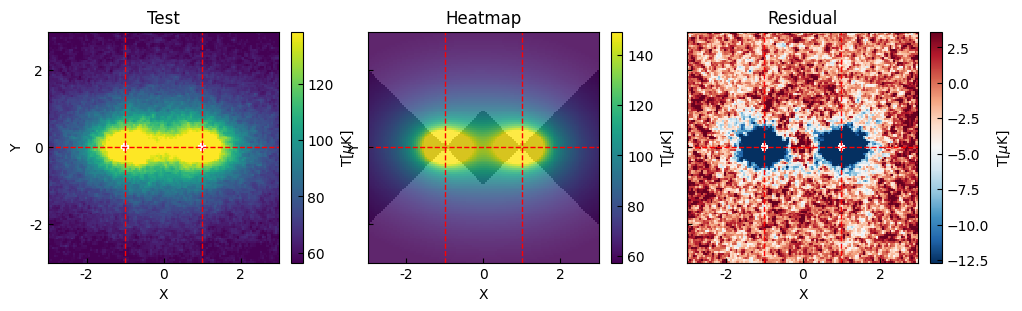

In [163]:
title = ['Test', 'Fitted', 'Residual']
axes =  plot_stack_fit_res(data_list_sector, title=title, fit_mask=mask_sector)
plot_axlines(ax=axes, vl=[40, 80], hl=[60])

<Axes: title={'center': 'Error Map'}, xlabel='X', ylabel='Y'>

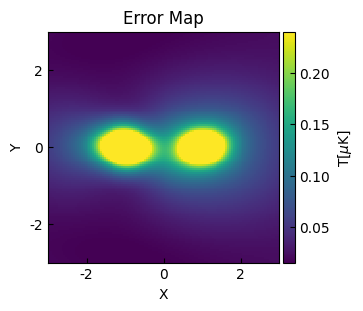

In [164]:
error_map = cov_to_err_map(fit_model, fit_info, *coord)
plot_heatmap(error_map, title='Error Map') 

# with mask square

<Axes: title={'center': 'Mask'}, xlabel='X', ylabel='Y'>

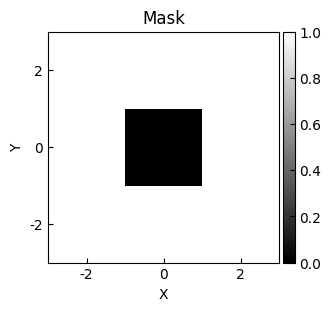

In [165]:
# mask_sq = ~get_mask_square(coord=coord)
mask_sq = ~get_mask_square(coord=coord, xlim=[-1, 1], ylim=[-1, 1])

plot_heatmap(mask_sq, title='Mask', cmap='gray', cbar_label='')

In [166]:
data_list_square, fit_model, fit_info = halofit(coord, data, model=model, mask=mask_sq, print_model=True, weights=weights[mask_sq])


Fitted double NFW model:
Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2]
Components: 
    [0]: <NFW2D(amplitude=3.26192041, x_mean=-1., y_mean=0., r_s=15.50406582, ellipticity=0.29823633, theta=-0.05869904)>

    [1]: <NFW2D(amplitude=2.58644556, x_mean=1., y_mean=0., r_s=19.86129014, ellipticity=0.29823633, theta=-0.01332178)>

    [2]: <Const2D(amplitude=43.28827274)>
Parameters:
      amplitude_0    x_mean_0 y_mean_0 ...        theta_1           amplitude_2   
    ---------------- -------- -------- ... --------------------- -----------------
    3.26192041174697     -1.0      0.0 ... -0.013321784878188638 43.28827273529828

Goodness of fit:
Chi-squared: 669588.168
Reduced chi-squared: 52.365
RMS residual: 7.236



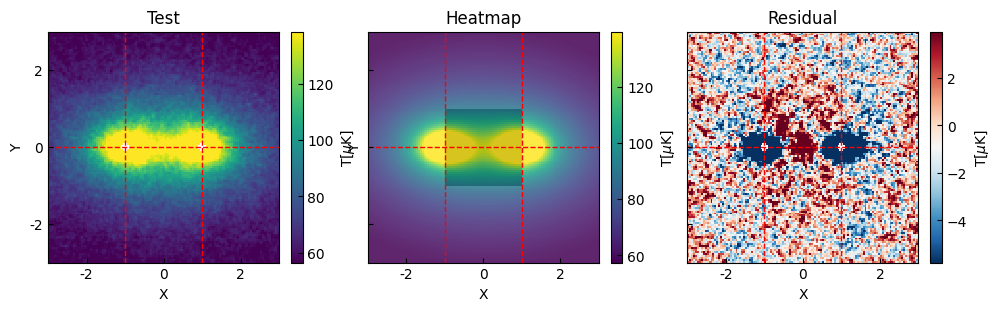

In [167]:
title = ['Test', 'Fitted', 'Residual']
axes =  plot_stack_fit_res(data_list_square, title=title, fit_mask=mask_sq)
# axes =  plot_stack_fit_res(data_list_square, title=title, fit_mask=mask_sq, vmax=[140,140, 20], vmin=[60, 60, -20])
plot_axlines(ax=axes, vl=[40, 80], hl=[60])

<Axes: title={'center': 'Error Map'}, xlabel='X', ylabel='Y'>

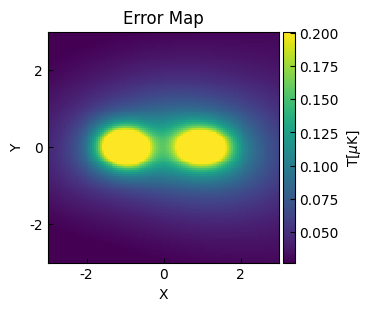

In [168]:
error_map = cov_to_err_map(fit_model, fit_info, *coord)
plot_heatmap(error_map, title='Error Map') 

# compare

(-100.0, 100.0)

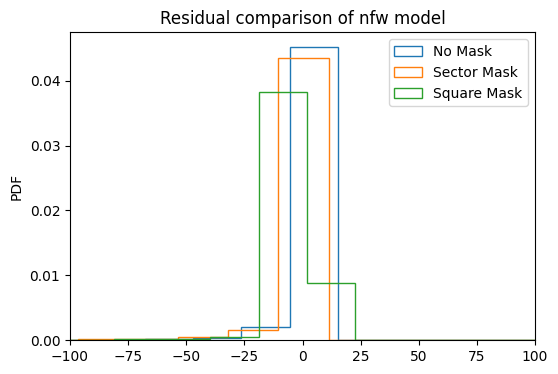

In [169]:
res_list = [data_list[-1].flatten(), data_list_sector[-1].flatten(), data_list_square[-1].flatten()]
labels = ['No Mask', 'Sector Mask', 'Square Mask']
title = 'Residual comparison of %s model' %(name)
ax = plot_hist(res_list, label=labels, bins=100, title=title)
ax.set_xlim(-100, 100)

# profiles

In [170]:
# stack_fit_res = data_list
# stack_fit_res = data_list_sector
stack_fit_res = data_list_square

In [171]:
get_yprofile = lambda dlist, ind: [x[ind,:] for x in dlist]
get_xprofile = lambda dlist, ind: [x[:,ind] for x in dlist]

lines_list = [
    get_yprofile(stack_fit_res[:2], 60),
    get_xprofile(stack_fit_res[:2], 40),
    get_xprofile(stack_fit_res[:2], 80),
]
title_list = ['Y=0', 'X=-1', 'X=1']

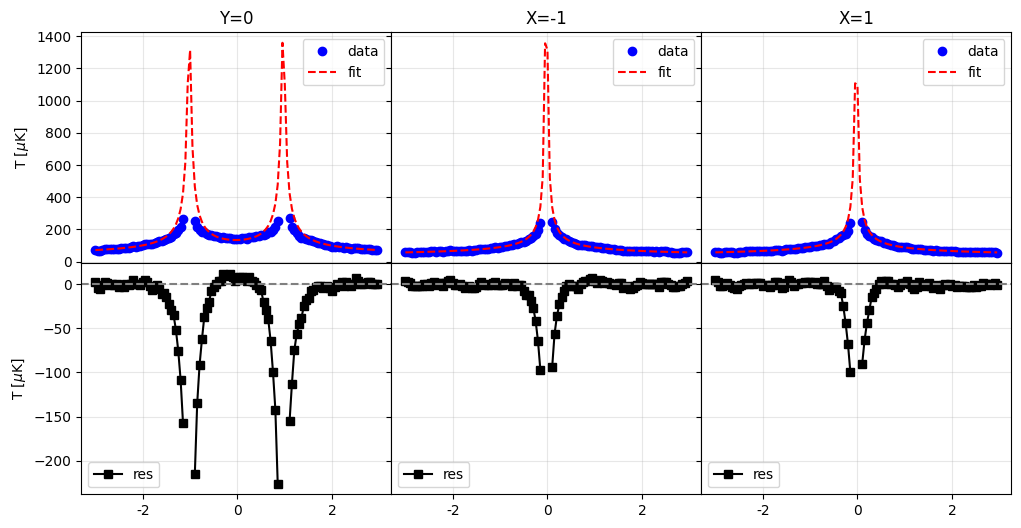

In [172]:
fig, axes = make_figure(2,3, figsize=(12,6), wspace=0., hspace=0.,aspect=None,sharex=True, sharey='row')

for i, lines in enumerate(lines_list):
    _axes = [axes[0,i], axes[1,i]]

    plot_line_diff(*lines, title=title_list[i], axes=_axes, labels=['data', 'fit', 'res'])

axes[0,0].set_ylabel(r'T [$\mu$K]')
axes[1,0].set_ylabel(r'T [$\mu$K]')
set_ticks(axes[1,0], share=False)

# estimate signal level

In [173]:
from mytools.estimate import get_signal_level
from mytools.plot import plot_profile_2c, plot_hist, make_figure
from mytools.data import read_h5

<Axes: title={'center': 'Weight'}, xlabel='X', ylabel='Y'>

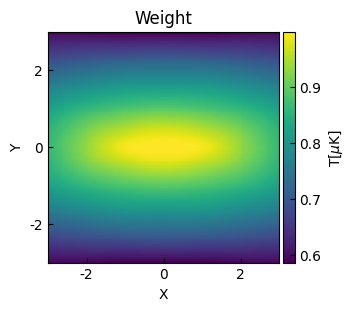

In [174]:
weight_path= '../data/pixcount_xsize3000_nfs10.h5'
pix_weights = read_h5(weight_path, 'tng_120k/weight')
# weights = read_h5(weight_path, 'crafts_122k/weight')
plot_heatmap(pix_weights, title='Weight', q=0.1)

Parameter names:
('amplitude_0', 'mean_0', 'stddev_0', 'amplitude_1')
Gauss fit parameters: [np.float64(4.019416268613955), np.float64(0.0), np.float64(0.24618372697531432), np.float64(0.29089918378422863)]
Gauss fit covariance: 
[[ 0.34081511 -0.01282659 -0.00865187]
 [-0.01282659  0.00131127 -0.00165327]
 [-0.00865187 -0.00165327  0.01762494]]
3 points clipped during sigma clipping.

Goodness of fit:
Chi-squared: 115.189
Reduced chi-squared: 0.985
RMS residual: 0.980

width: 0.24618372697531432
width_pix: 5


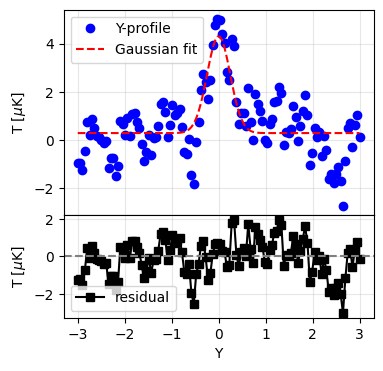

In [175]:
res = stack_fit_res[-1]
# bounds = (
#     [0, 0.1, -np.inf],
#     [np.inf, 0.7, np.inf],
# )
bounds = {
    "amplitude_0": (-np.inf, np.inf),  # amp > 0
    "stddev_0": (0.01, 0.75),  # sigma
}
lx, ly, clrb, params, cov = get_signal_level(res, weights=pix_weights, bounds=bounds, sigma_clip_sigma=3, show_fit=True);
# lx, ly, clrb, params, cov = get_signal_level(res, bounds=bounds, sigma_clip_sigma=5, weights=weight[:,50:70].mean(axis=1), show_fit=False);
# lx, ly, clrb, params, cov = get_signal_level(res);

array([<Axes: title={'center': 'Transverse-section profile'}, xlabel='Y', ylabel='$T$[$\\mu$K]'>,
       <Axes: title={'center': 'Lengthwise-section profile'}, xlabel='X'>],
      dtype=object)

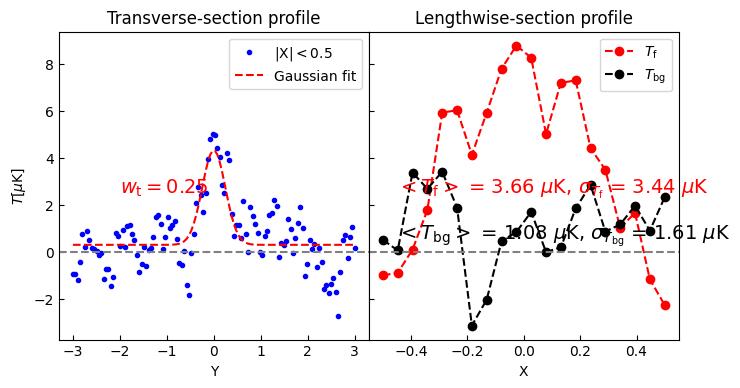

In [176]:
text_pos = [
    [-0.45, 0.5 * np.max(ly[0])], 
    [-0.45, -0.2* np.min(ly[0])], 
    [-2, 0.5 * np.max(ly[0])],
]
fig, axes = make_figure(1, 2, figsize=(8,4),wspace=0.,aspect=None,sharex=False)
plot_profile_2c(lx, ly, axes=axes, width=params[2], text_pos=text_pos)

<Axes: title={'center': 'Signal level'}, ylabel='PDF'>

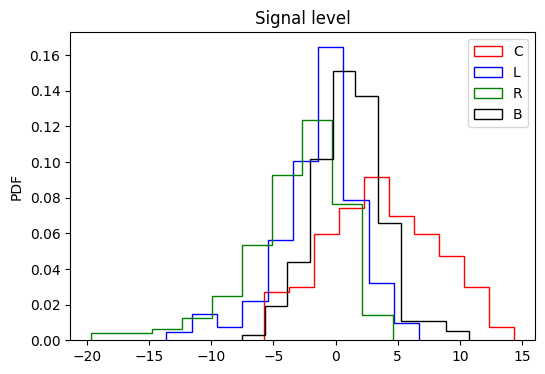

In [177]:
plot_hist(clrb, label=['C','L','R','B'], color=['r', 'b','g','k'], title='Signal level')